<a href="https://colab.research.google.com/github/NadiyaNowshin/Deep-Learning-Project-Handwritten-Digit-Classifier-MNIST-/blob/main/Deep_Learning_Project_Handwritten_Digit_Classifier_(MNIST).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning Project: Handwritten Digit Classifier (MNIST)

## 1. Introduction

The objective of this project is to build and evaluate a deep learning model that classifies handwritten digits from 0 to 9 using the MNIST dataset.

The MNIST dataset contains grayscale images of handwritten digits. Each image has a resolution of 28 × 28 pixels. A neural network will learn patterns from these images and predict the correct digit for each input image.

This project uses TensorFlow and Keras to implement a deep neural network with batch normalization and dropout regularization.

## 2. Project Objectives

The main objectives of this project are:

- Load the MNIST dataset using TensorFlow/Keras.
- Explore the dataset and visualize handwritten digits.
- Normalize pixel values to the range [0, 1].
- Flatten the images for use in a fully connected neural network.
- Build a deep neural network with hidden layers.
- Apply batch normalization to improve training stability.
- Apply dropout to reduce overfitting.
- Train the model using a validation dataset.
- Visualize training and validation accuracy and loss.
- Evaluate the final model using the test dataset.

## 3. Tools and Technologies

- Python
- Google Colab
- TensorFlow and Keras
- NumPy
- Matplotlib
- Scikit-learn

## 4. Dataset Description

The MNIST dataset consists of 70,000 grayscale images of handwritten digits.

- Training images: 60,000
- Test images: 10,000
- Image dimensions: 28 × 28 pixels
- Number of classes: 10
- Class labels: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9

Each image belongs to one of ten digit classes. The model learns to associate image patterns with their corresponding digit labels.

In [ ]:
# Import the required libraries

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Flatten,
    Dense,
    BatchNormalization,
    Dropout
)
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


## 5. Importing Libraries

The required Python libraries are imported to load the dataset, build the neural network, train the model, and visualize the results.

- **NumPy:** Performs numerical operations on arrays.
- **Matplotlib:** Creates graphs and visualizations.
- **TensorFlow/Keras:** Builds and trains the deep learning model.
- **Scikit-learn:** Provides evaluation metrics such as the classification report and confusion matrix.
- **Seaborn:** Creates a heatmap for visualizing the confusion matrix.

The TensorFlow version is displayed to identify the software environment used for the experiment.

## 6. Dataset Loading

The MNIST dataset is available directly through the TensorFlow/Keras API. It is divided into training and test sets.

The training set is used to learn the model parameters, while the test set is reserved for evaluating the model's performance on unseen images.

The dataset contains grayscale images with pixel intensities ranging from 0 to 255 before preprocessing.

In [ ]:
# Load the MNIST dataset

(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Display dataset shapes
print("Training images shape:", x_train.shape)
print("Training labels shape:", y_train.shape)

print("Test images shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

# Display pixel value range
print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Training images shape: (60000, 28, 28)
Training labels shape: (60000,)
Test images shape: (10000, 28, 28)
Test labels shape: (10000,)
Minimum pixel value: 0
Maximum pixel value: 255


Interpretation: The training dataset contains 60,000 images, while the test dataset contains 10,000 images. Each image has 28 rows and 28 columns of grayscale pixel values.

#Visualize sample images

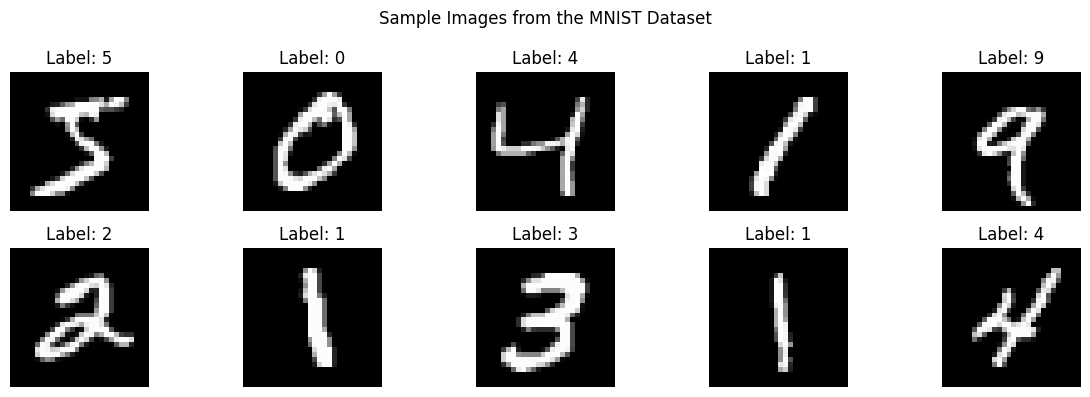

In [ ]:
# Display the first 10 images from the training dataset

plt.figure(figsize=(12, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Sample Images from the MNIST Dataset")
plt.tight_layout()
plt.show()

### Dataset Exploration

The dataset shapes indicate that the training set contains 60,000 images and the test set contains 10,000 images. Each image is represented by a 28 × 28 matrix.

The labels contain the correct digit for each image. Visualizing sample images helps verify that the dataset has loaded correctly and that the labels correspond to the handwritten digits.

The images are grayscale, so each pixel is represented by a single intensity value.

## 7. Data Preprocessing

Data preprocessing transforms the raw images into a format suitable for training a neural network.

### 7.1 Normalization

The original pixel values range from 0 to 255. Dividing each pixel value by 255 converts the values to the range [0, 1].

Normalization helps maintain a consistent input scale and can improve the optimization process during neural network training.

### 7.2 Flattening

Each image has dimensions of 28 × 28 pixels. A fully connected neural network requires a one-dimensional feature vector as its input.

Therefore, each image is flattened into a vector containing 784 features.

### 7.3 One-Hot Encoding

The target labels are converted into one-hot encoded vectors. Each label is represented by a vector of length 10, where the correct class has a value of 1 and all other classes have a value of 0.

This representation is used with the categorical cross-entropy loss function.

In [ ]:
from tensorflow.keras.utils import to_categorical

# Normalize pixel values to the range [0, 1]

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten 28 x 28 images into 784-dimensional vectors

x_train = x_train.reshape(x_train.shape[0], 784)
x_test = x_test.reshape(x_test.shape[0], 784)

# Convert integer labels into one-hot encoded vectors

y_train_encoded = to_categorical(y_train, num_classes=10)
y_test_encoded = to_categorical(y_test, num_classes=10)

# Display the shapes after preprocessing

print("Training images shape:", x_train.shape)
print("Test images shape:", x_test.shape)

print("Training labels shape:", y_train_encoded.shape)
print("Test labels shape:", y_test_encoded.shape)

print("Normalized pixel range:", x_train.min(), "to", x_train.max())

Training images shape: (60000, 784)
Test images shape: (10000, 784)
Training labels shape: (60000, 10)
Test labels shape: (10000, 10)
Normalized pixel range: 0.0 to 0.003921569


### Preprocessing Results

After preprocessing, each image contains 784 normalized features, and each label is represented by a 10-element one-hot encoded vector.

Normalization reduces the magnitude of the input values, flattening converts the two-dimensional image into a feature vector, and one-hot encoding prepares the target labels for multiclass classification.

The original integer labels are retained separately for evaluation and interpretation.

## 8. Model Architecture

A fully connected deep neural network is implemented using the Keras Sequential API.

The network consists of three hidden layers and one output layer.


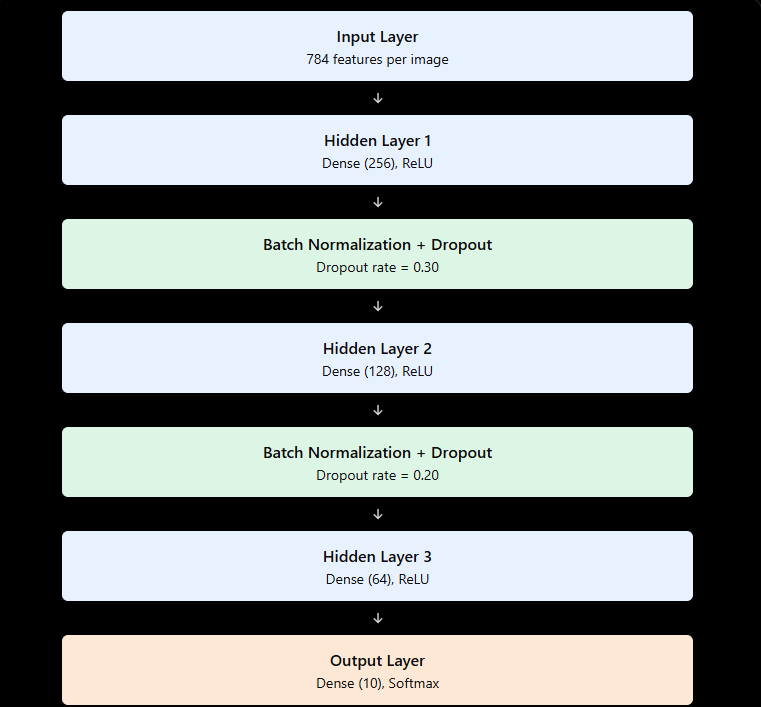

In [ ]:
# Build the neural network

model = Sequential([
    Input(shape=(784,)),

    # Hidden layer 1
    Dense(256, activation="relu"),
    BatchNormalization(),
    Dropout(0.30),

    # Hidden layer 2
    Dense(128, activation="relu"),
    BatchNormalization(),
    Dropout(0.20),

    # Hidden layer 3
    Dense(64, activation="relu"),

    # Output layer for 10 digit classes
    Dense(10, activation="softmax")
])

# Display the model architecture

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 244,298 (954.29 KB)

 Trainable params: 243,530 (951.29 KB)

 Non-trainable params: 768 (3.00 KB)

### Model Summary

The model summary displays the layers, output shapes, and number of trainable and non-trainable parameters.

The network accepts a vector of 784 features and returns 10 class probabilities.

The hidden layers use ReLU to introduce nonlinearity. Batch normalization helps stabilize the intermediate activations, while dropout provides regularization. The softmax output supports classification into ten mutually exclusive digit classes.

## 9. Model Compilation

Before training, the model must be compiled with a loss function, optimizer, and evaluation metric.

- **Loss function:** Categorical cross-entropy measures the difference between the true one-hot encoded labels and predicted class probabilities.
- **Optimizer:** Adam updates the model's weights to minimize the loss.
- **Metric:** Accuracy measures the proportion of correctly classified examples.

## 10. Model Training

The model is trained for 15 epochs with a batch size of 128.

A validation split of 10% is used to monitor performance on data that is not used for gradient updates. The remaining 90% of the supplied training data is used for weight optimization.

Training and validation accuracy and loss are recorded in the history object for later visualization.

The test set remains separate and is not used to fit the model or select its parameters.

In [ ]:
# Compile the model

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
# Train the model

history = model.fit(
    x_train,
    y_train_encoded,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.8857 - loss: 0.3814 - val_accuracy: 0.2245 - val_loss: 1.7031
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9367 - loss: 0.2041 - val_accuracy: 0.9625 - val_loss: 0.1241
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9484 - loss: 0.1669 - val_accuracy: 0.9687 - val_loss: 0.1022
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9535 - loss: 0.1486 - val_accuracy: 0.9700 - val_loss: 0.1003
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9564 - loss: 0.1352 - val_accuracy: 0.9748 - val_loss: 0.0871
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9608 - loss: 0.1239 - val_accuracy: 0.9750 - val_loss: 0.0782
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - accuracy: 0.9619 - loss: 0.1197 - val_accuracy: 0.9757 - val_loss: 0.0839
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9636 - loss: 0.1142 - val_accurac

### Training Process

During each epoch, the model processes the training examples in mini-batches, calculates the loss, and updates its weights using the Adam optimizer.

The validation data is used to assess generalization after each epoch without updating the weights from those validation examples.

The training history stores four important measurements:

- `accuracy`: Training accuracy for each epoch.
- `val_accuracy`: Validation accuracy for each epoch.
- `loss`: Training loss for each epoch.
- `val_loss`: Validation loss for each epoch.

These measurements help determine whether the model is learning effectively and whether there are signs of overfitting.

## 11. Training and Validation Accuracy

Training accuracy measures the proportion of correctly classified training examples. Validation accuracy measures performance on the held-out validation examples.

Plotting both metrics across epochs helps us understand how the model learns and whether its performance generalizes beyond the data used for weight updates.

If both curves improve and remain relatively close, the model may be generalizing well. If training accuracy continues to improve while validation accuracy stagnates or decreases, this may indicate overfitting.

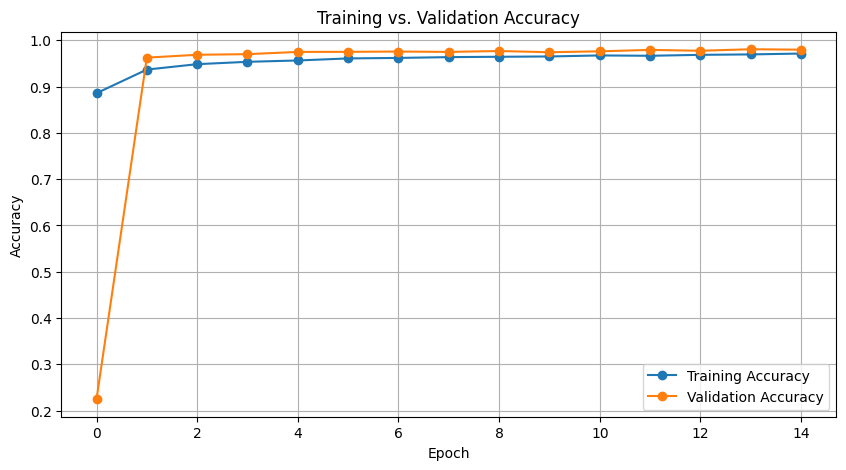

In [ ]:
# Plot training and validation accuracy

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Training vs. Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

## 12. Training and Validation Loss

Loss measures how far the model's predictions are from the correct labels according to the chosen loss function.

A decreasing training loss indicates that the model is fitting the training data. Validation loss provides information about performance on unseen validation examples.

If training loss decreases while validation loss begins to rise, the model may be overfitting. Both accuracy and loss should be considered when assessing the learning process.

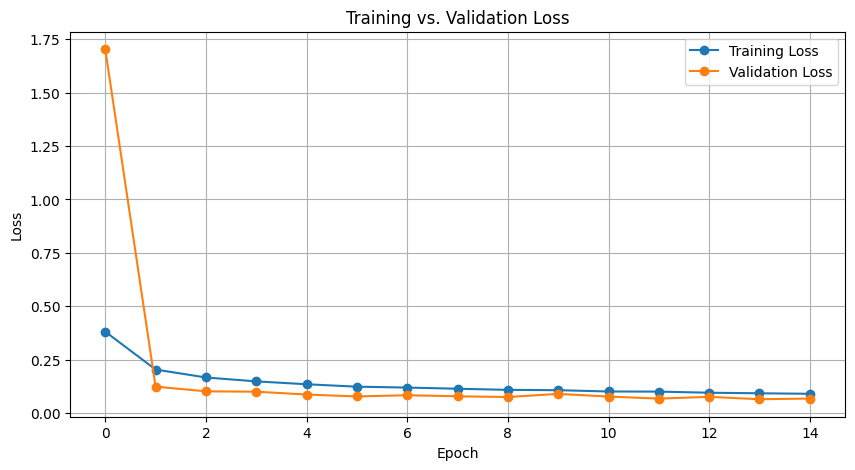

In [ ]:
# Plot training and validation loss

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Training vs. Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

### Interpretation of Training Results

The training and validation accuracy curves show how the model's classification performance changes over the training epochs. The training accuracy reached **[insert final training accuracy]**, while the validation accuracy reached **[insert final validation accuracy]**.

The training and validation loss curves provide additional information about the optimization process. The final training loss was **[insert final training loss]**, and the final validation loss was **[insert final validation loss]**.

Based on these plots, **[describe whether accuracy improved, whether the curves remained close, and whether there were signs of overfitting]**.

The final observations should be based on the actual plots generated during training.

## 13. Model Evaluation

After training, the model is evaluated on the independent test dataset containing 10,000 images.

The test dataset was not used for training or validation. It provides an estimate of how well the model classifies previously unseen handwritten digits.

The evaluation reports test loss and test accuracy. A classification report and confusion matrix are also used to examine performance across the ten digit classes.

In [ ]:
# Evaluate the model on the test dataset

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test_encoded,
    verbose=0
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy Percentage: {test_accuracy * 100:.2f}%")

Test Loss: 0.0728
Test Accuracy: 0.9779
Test Accuracy Percentage: 97.79%


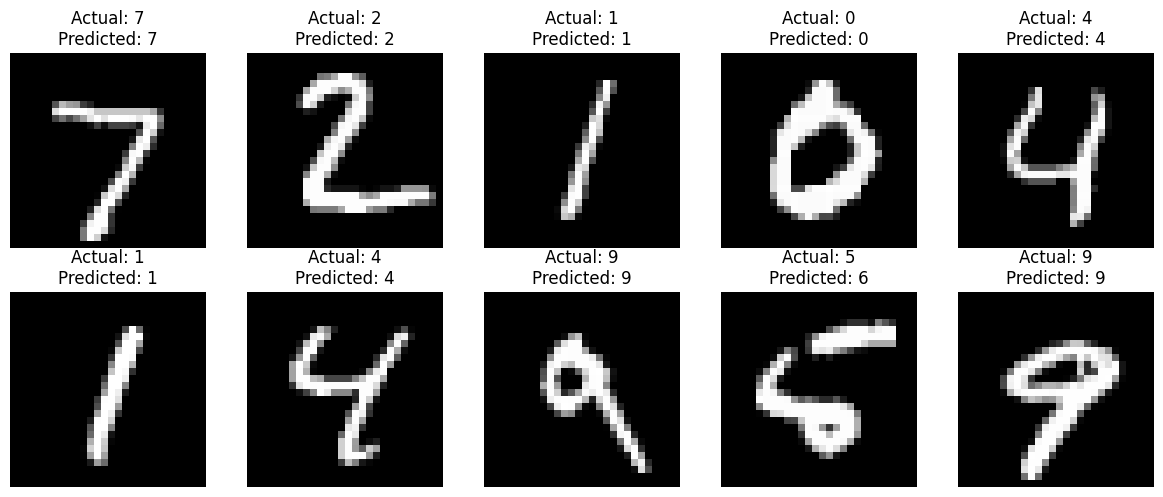

In [ ]:
# Predict class probabilities for the test images

y_pred_prob = model.predict(x_test, verbose=0)

# Convert predicted probabilities into digit labels

y_pred = np.argmax(y_pred_prob, axis=1)

# Display sample predictions

plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    # Reshape the flattened image for visualization
    plt.imshow(x_test[i].reshape(28, 28), cmap="gray")

    predicted_label = y_pred[i]
    actual_label = y_test[i]

    plt.title(
        f"Actual: {actual_label}\nPredicted: {predicted_label}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

### Prediction Results

The trained model generates ten probability scores for each test image, representing the predicted probabilities of the digit classes 0 through 9.

The `argmax()` function selects the class with the highest probability. The predicted labels are compared with the actual test labels to examine whether the model classifies the images correctly.

Visualizing sample predictions makes it easier to identify examples where the model succeeds or makes mistakes.

In [ ]:
# Display precision, recall, and F1-score for each digit class

print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(10)),
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.97      0.99      0.98      1032
           3       0.97      0.97      0.97      1010
           4       0.97      0.98      0.98       982
           5       0.98      0.97      0.97       892
           6       0.98      0.99      0.98       958
           7       0.98      0.97      0.98      1028
           8       0.98      0.97      0.97       974
           9       0.98      0.97      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



### Classification Metrics

The classification report provides three important metrics for each digit class.

- **Precision:** The proportion of predictions for a class that are correct.
- **Recall:** The proportion of actual examples of a class that are correctly identified.
- **F1-score:** The harmonic mean of precision and recall.

Support indicates the number of actual test examples belonging to each class. These metrics help identify classes that may be more difficult for the model to classify.

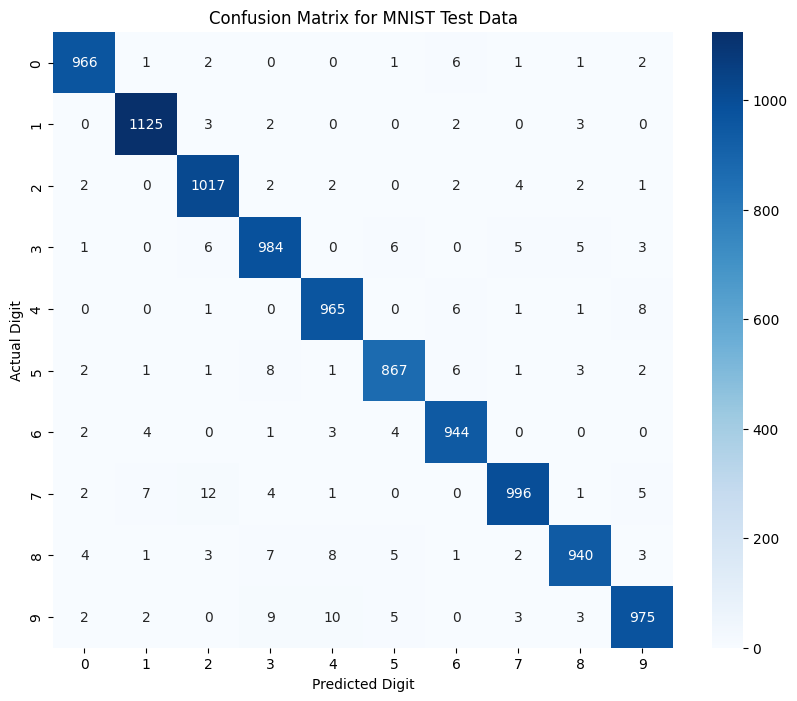

In [ ]:
# Generate the confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(10))
)

# Visualize the confusion matrix

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title("Confusion Matrix for MNIST Test Data")
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.show()

### Confusion Matrix Interpretation

The confusion matrix compares actual digit labels with predicted digit labels.

Rows represent the actual classes, and columns represent the predicted classes. Values on the main diagonal indicate correctly classified examples. Values outside the diagonal indicate misclassifications.

The matrix helps identify which digits the model distinguishes effectively and which digit pairs it confuses most often.

In [ ]:
# Display the final model performance

print("FINAL MODEL RESULTS")
print("-" * 35)

print(f"Epochs trained: {len(history.history['accuracy'])}")
print(f"Final training accuracy: {history.history['accuracy'][-1] * 100:.2f}%")
print(f"Final validation accuracy: {history.history['val_accuracy'][-1] * 100:.2f}%")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print(f"Test loss: {test_loss:.4f}")

FINAL MODEL RESULTS
-----------------------------------
Epochs trained: 15
Final training accuracy: 97.13%
Final validation accuracy: 97.97%
Test accuracy: 97.79%
Test loss: 0.0728


## 14. Conclusion

In this project, a deep learning model was developed to classify handwritten digits from 0 to 9 using the MNIST dataset and TensorFlow/Keras.

The dataset was preprocessed by normalizing pixel values, flattening the images, and one-hot encoding the target labels. A fully connected neural network with three hidden layers was implemented using ReLU activation functions, batch normalization, and dropout regularization.

The model was trained using the Adam optimizer and categorical cross-entropy loss. Training and validation accuracy and loss were visualized to understand the learning process and assess possible overfitting.

The final model achieved a test accuracy of **[insert actual test accuracy]%** on the independent test dataset.

The classification report and confusion matrix provided further insight into the model's performance across the ten digit classes.

Overall, this project demonstrates how deep learning can be applied to image classification and illustrates the roles of data preprocessing, batch normalization, dropout, model training, and performance evaluation.